# manydream walkthrough

This notebook runs the whole methodology of *Probabilistic modelling of general noisy multi-manifold data sets* (Canducci, Tiňo, Mastropietro, 2022) step by step on the paper's mixed-manifold data set **D1**, and then on a set of one-dimensional filaments.

The steps are: **preprocess** (diffuse + filter) → **dimensionality index** → **graphs** (manifold crawling) → **Abstract GTM** (density model).

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
import manydream
from manydream import datasets, viz

plt.rcParams["figure.dpi"] = 70
warnings.simplefilter("ignore", manydream.DegenerateModelWarning)

## 1. Data

Two curves, four surfaces and a 3-D blob, cut out of a uniform cloud, plus twice as many background-noise points. `label` and `dim` hold the ground truth and are only used for checking.

(105096, 3) {'noise': np.int64(70064), 'parabolic arm': np.int64(364), 'spiral': np.int64(821), 'S-shape': np.int64(8343), 'hyperbolic cap': np.int64(2269), 'torus': np.int64(19065), 'Moebius strip': np.int64(2206), 'blob': np.int64(1964)}


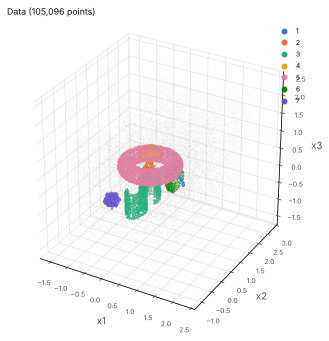

In [2]:
ds = datasets.make_d1(random_state=0)
X = ds.X
print(X.shape, dict(zip(ds.names, np.bincount(ds.label))))
viz.plot_data(X, labels=ds.label);

## 2. The characteristic scale `r`

`r` is the radius of every local neighbourhood. It has to be larger than the thickness of the noise around the structures and smaller than the gap between separate structures. Here `r = 0.1`.

In [3]:
r = 0.1

## 3. Preprocessing

SAF diffusion pulls points towards the cores of the structures; the density filter then removes points whose neighbourhood is sparse. The histogram shows the neighbour counts within the filter radius (`r / 2`): the threshold has to sit between the background peak and the structures.

Any object implementing `manydream.preprocess.Preprocessor` can replace these two steps.

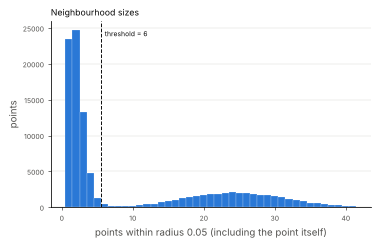

In [4]:
viz.plot_density_counts(X, r / 2, min_points=6);

kept 37,531 of 105,096 points; background surviving: 3.6%


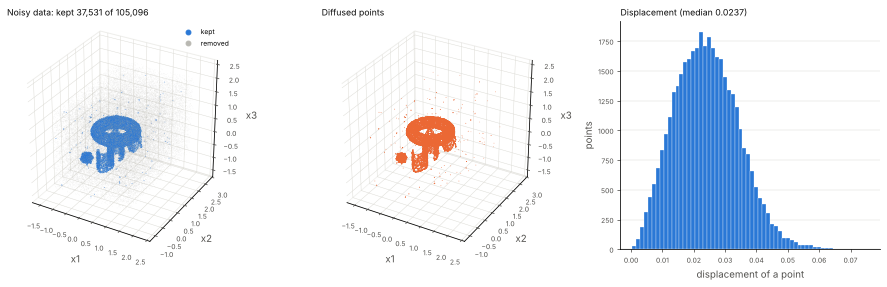

In [5]:
pre = manydream.Pipeline([manydream.SAF(), manydream.DensityFilter()]).fit_transform(X, r)
kept = np.isin(np.arange(len(X)), pre.indices)
print(f"kept {len(pre):,} of {len(X):,} points; background surviving: {kept[ds.label == 0].mean():.1%}")
viz.plot_preprocess(X, pre);

## 4. Dimensionality index

Local PCA in balls of radius `r` on the diffused points. The normalised spectrum is compared with the ideal spectra of 1-, 2-, ..., d-dimensional neighbourhoods on the probability simplex, then smoothed spatially.

{0: 250, 1: 1772, 2: 33449, 3: 2060}


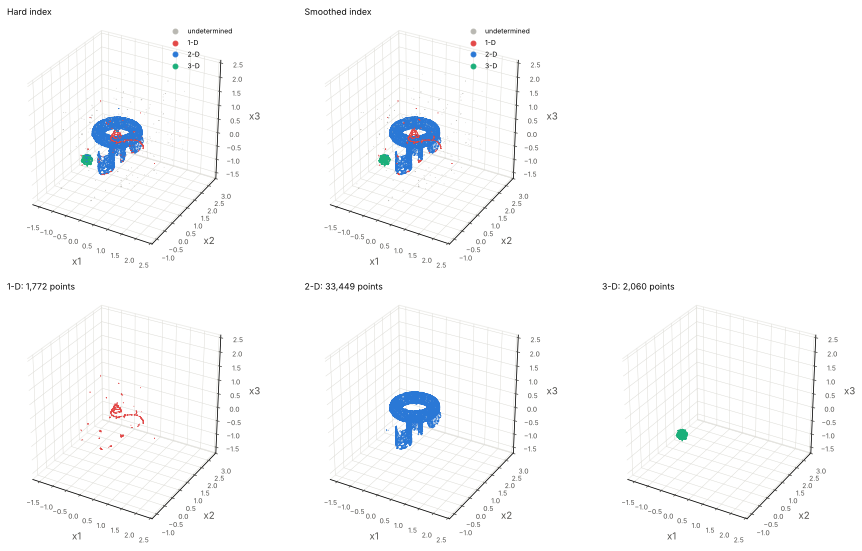

In [6]:
dim = manydream.dimensionality_index(pre.diffused, r)
print(dim.counts_per_dim())
viz.plot_dim_index(pre.diffused, dim);

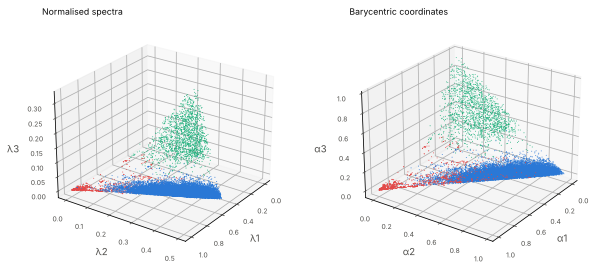

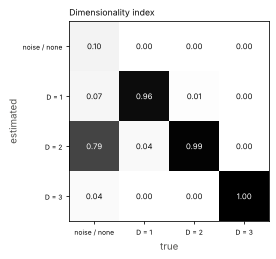

In [7]:
viz.plot_simplex(dim)
viz.plot_confusion(dim.index, ds.dim[pre.indices]);

## 5–6. Graphs and density models with the one-call estimator

`MultiManifoldLearner` chains all stages and keeps every intermediate result. It reuses the same defaults as above, so the first two stages reproduce what we just did.

In [8]:
learner = manydream.MultiManifoldLearner(r=r, random_state=0, verbose=True).fit(X)
print(learner.summary())

[manydream] preprocess: kept 37531 of 105096 points (1.52s)


[manydream] dimension: {0: 250, 1: 1772, 2: 33449, 3: 2060} (0.16s)


[manydream] graphs: 3 of dim 1, 4 of dim 2 (0.06s)


[manydream] agtm: 7 models (15.30s)


MultiManifoldLearner: 105096 points in 3-D, r = 0.1
  preprocess : kept 37531 points (35.7%)
  dimension  : 250 undetermined, 1772 x 1-D, 33449 x 2-D, 2060 x 3-D
  graphs     : 3 of dim 1, 4 of dim 2
  manifold 0 : Manifold(dim=1, nodes=21, edges=20, points=558, loglik=4.08)
  manifold 1 : Manifold(dim=1, nodes=18, edges=17, points=394, loglik=4.55)
  manifold 2 : Manifold(dim=1, nodes=15, edges=14, points=394, loglik=4.18)
  manifold 3 : Manifold(dim=2, nodes=1066, edges=1841, points=20208, loglik=0.966)
  manifold 4 : Manifold(dim=2, nodes=411, edges=707, points=8508, loglik=1.79)
  manifold 5 : Manifold(dim=2, nodes=115, edges=202, points=2386, loglik=3.04)
  manifold 6 : Manifold(dim=2, nodes=113, edges=187, points=2288, loglik=3.04)


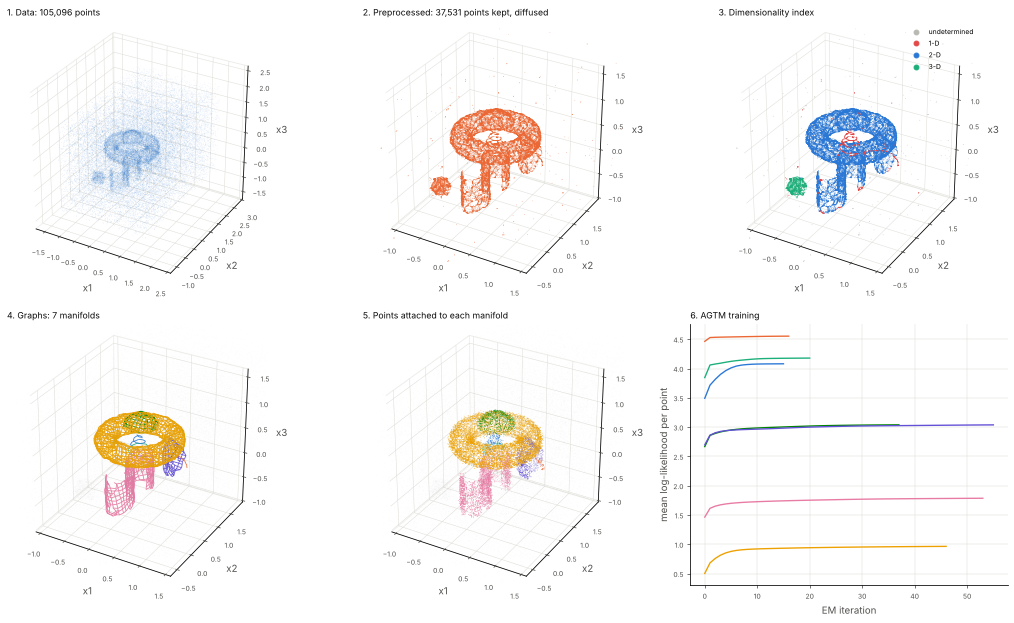

In [9]:
viz.plot_summary(learner);

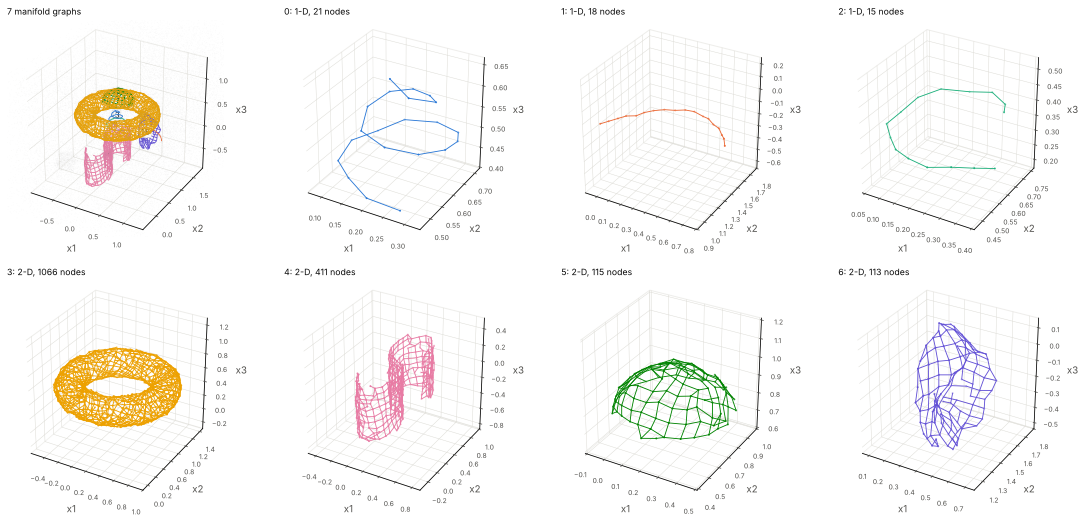

In [10]:
viz.plot_graphs(learner, X, panels=True);

Each manifold carries its graph, its fitted `AGTM` and the indices of the points attached to it. The ground truth confirms that every graph follows a single structure:

In [11]:
for k, m in enumerate(learner.manifolds_):
    counts = np.bincount(ds.label[m.point_indices], minlength=len(ds.names))
    print(k, m, "->", ds.names[counts[1:].argmax() + 1], f"({counts[1:].max() / counts.sum():.0%} pure)")

0 Manifold(dim=1, nodes=21, edges=20, points=558, loglik=4.08) -> spiral (93% pure)
1 Manifold(dim=1, nodes=18, edges=17, points=394, loglik=4.55) -> parabolic arm (92% pure)
2 Manifold(dim=1, nodes=15, edges=14, points=394, loglik=4.18) -> spiral (92% pure)
3 Manifold(dim=2, nodes=1066, edges=1841, points=20208, loglik=0.966) -> torus (94% pure)
4 Manifold(dim=2, nodes=411, edges=707, points=8508, loglik=1.79) -> S-shape (94% pure)
5 Manifold(dim=2, nodes=115, edges=202, points=2386, loglik=3.04) -> hyperbolic cap (94% pure)
6 Manifold(dim=2, nodes=113, edges=187, points=2288, loglik=3.04) -> Moebius strip (93% pure)


### The density model

The AGTM puts one Gaussian on every graph node, aligned with the manifold. Ellipses show a sample of them; the curves show the EM log-likelihood (monotone by construction).

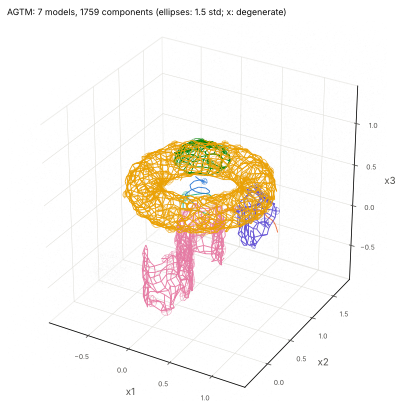

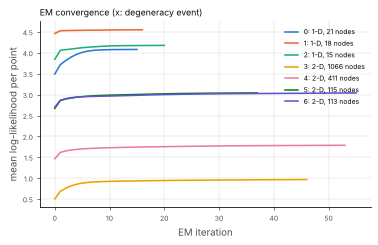

In [12]:
viz.plot_agtm(learner, X)
viz.plot_loglik(learner);

In [13]:
print("mean log-density of manifold points :", round(learner.score(X[ds.label > 0]), 2))
print("mean log-density of background noise:", round(learner.score(X[ds.label == 0]), 2))

mean log-density of manifold points : -4.7


mean log-density of background noise: -229.52


### Curvature

The smooth mapping from the abstract graph to data space gives a curvature along every edge. On the torus the largest principal curvature is one over the tube radius (0.18 after scaling), about 5.6; the estimate is of that order, somewhat raised by the noise the fitted surface follows. The unfolded view shows the abstract graph in the plane.

median curvature: 8.11


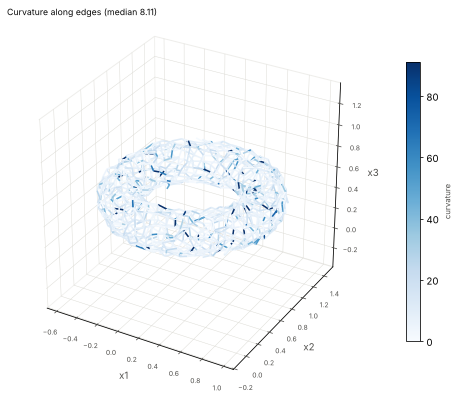

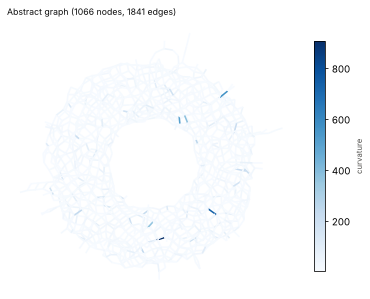

In [14]:
torus = max(learner.manifolds_, key=lambda m: m.graph.n_nodes)
c = torus.agtm.edge_curvature()
print("median curvature:", round(float(np.median(c)), 2))
viz.plot_curvature(torus)
viz.plot_unfolded(torus, c, label="curvature");

### Changing a parameter

Only the stages that depend on the changed parameter are recomputed. Here the basis functions of the AGTM are made coarser (`epsilon = 2`): preprocessing, dimensionality index and graphs are reused.

In [15]:
learner.set_params(epsilon=2)
print("stale stages:", learner.stale_stages)
learner.run()
print({k: round(v, 2) for k, v in learner.timings_.items()})

stale stages: ('agtm',)


[manydream] agtm: 7 models (8.77s)


{'preprocess': 1.52, 'dimension': 0.16, 'graphs': 0.06, 'agtm': 8.77}


## One-dimensional manifolds (filaments)

For `dim = 1` the graphs are chains, and quantities can be profiled along the arc length — the 1-DREAM use case. The set below holds a spiral, a circle (found as a closed chain of length 2π · 0.45 ≈ 2.83) and a parabolic arc in background noise.

MultiManifoldLearner: 19242 points in 3-D, r = 0.1
  preprocess : kept 9863 points (51.3%)
  dimension  : 6 undetermined, 9857 x 1-D
  graphs     : 3 of dim 1
  manifold 0 : Manifold(dim=1, nodes=96, edges=95, points=6161, loglik=3.33)
  manifold 1 : Manifold(dim=1, nodes=38, edges=38, points=2426, loglik=4.39)
  manifold 2 : Manifold(dim=1, nodes=21, edges=20, points=1270, loglik=5.03)
{'filament': 0, 'nodes': 96, 'length': 6.90352948606531, 'points': 6161, 'closed': False}
{'filament': 1, 'nodes': 38, 'length': 2.8281976570987863, 'points': 2426, 'closed': True}
{'filament': 2, 'nodes': 21, 'length': 1.4403336831327507, 'points': 1270, 'closed': False}


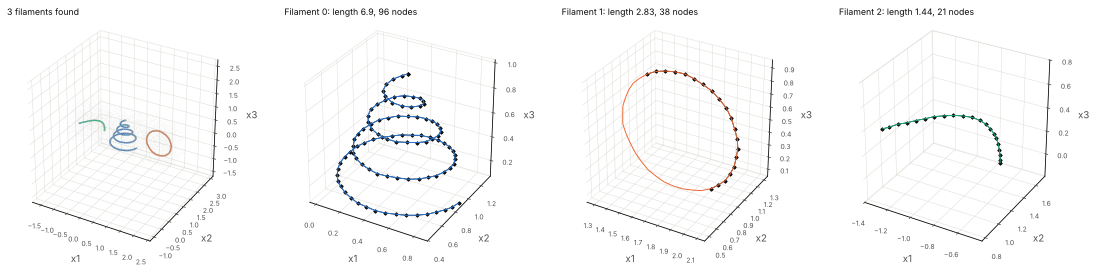

In [16]:
fs = datasets.make_filaments(random_state=0)
fl = manydream.MultiManifoldLearner(r=0.1, dims=[1], random_state=0).fit(fs.X)
print(fl.summary())
for row in viz.filament_table(fl):
    print(row)
viz.plot_filaments(fl, fs.X);

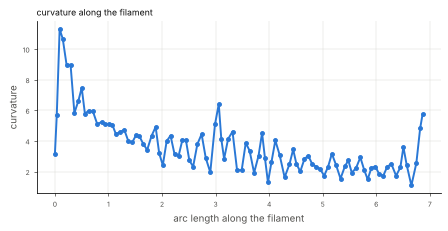

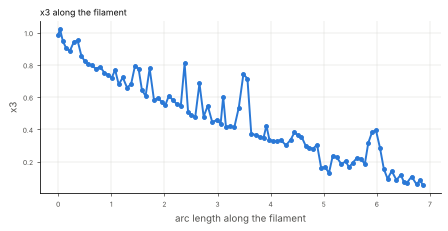

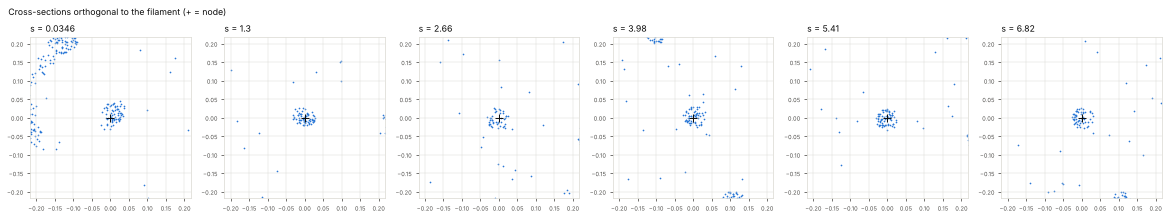

In [17]:
longest = max(fl.manifolds_, key=lambda m: m.graph.total_length())
viz.plot_profile(longest)                                   # curvature along the filament
viz.plot_profile(longest, fs.X, fs.X[:, 2], label="x3")    # any per-point quantity
viz.plot_cross_sections(longest, fs.X);

## Saving

`manydream.io.save(learner, "model.pkl")` stores the fitted pipeline; `manydream.io.load` restores it. The same steps are available interactively with `manydream-gui`.